# Calibrazione microfono Behringer ECM8000

La differenza in dB fra la risposta misurata di un riferimento (sorgente nota) e la sua curva di datasheet è la non-linearità del microfono, a meno della catena audio già compensata via loopback.

- `data/reference/YamahaHS5_datasheet.csv` — curva di riferimento digitalizzata da WebPlotDigitizer, colo colonne 3 e 4.
- `data/calibration/txt/Cal_ESS_02_ECM8000.txt` — export REW della misura del riferimento con ECM8000.

**File di calibrazione prodotto:** `data/calibration/ecm8000_mic.cal`

## Caricamento e pulizia del riferimento (HS5 datasheet)

Lettura dataset CSV: `np.genfromtxt` con `filling_values=np.nan` gestisce le righe vuote. I dati vengono ordinati in frequenza per eventuali errori in fase di digitalizzazione.

96 punti, 20.8–19521.9 Hz


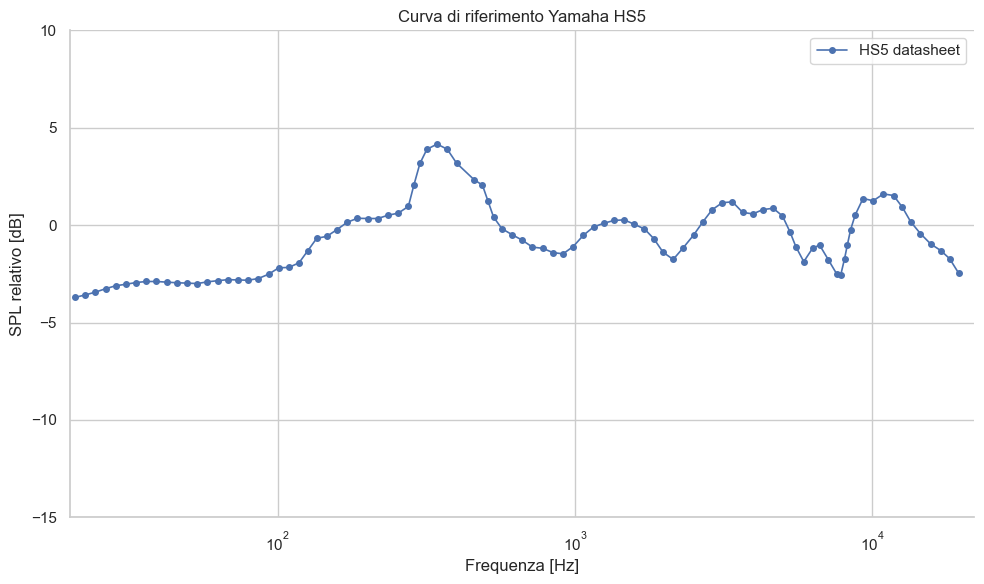

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent / 'src'))
from rew_io import (CAL_DIR, CAL_TXT_DIR, REF_DIR, FIG_DIR, load_rew_export,
                    write_cal_file, frac_octave_smooth, log_taper)

sns.set_theme(style='whitegrid', rc={'axes.spines.top': False, 'axes.spines.right': False})
C = sns.color_palette('deep')

REF_FILE = REF_DIR / 'YamahaHS5_datasheet.csv'
ref = np.genfromtxt(REF_FILE, delimiter=',', skip_header=2, usecols=(2, 3), filling_values=np.nan)
ref = ref[(ref[:, 0] >= 20) & (ref[:, 0] <= 22000) & np.isfinite(ref[:, 1])]
f_ref, dB_ref = ref[np.argsort(ref[:, 0])].T
print(f'{len(f_ref)} punti, {f_ref.min():.1f}–{f_ref.max():.1f} Hz')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(f_ref, dB_ref, 'o-', ms=4, lw=1.2, color=C[0], label='HS5 datasheet')
ax.set(xscale='log', xlim=(20, 22000), ylim=(-15, 10), xlabel='Frequenza [Hz]',
       ylabel='SPL relativo [dB]', title='Curva di riferimento Yamaha HS5')
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / 'curva_riferimento_hs5.png', dpi=200)
plt.show()

## Verifica della calibrazione loopback della scheda audio

Confronto tra sweep con e senza file di calibrazione della scheda audio. L'acquisizione con file `.cal` caricato deve risultare piatta (entro ±0.2 dB) se la calibrazione è corretta.

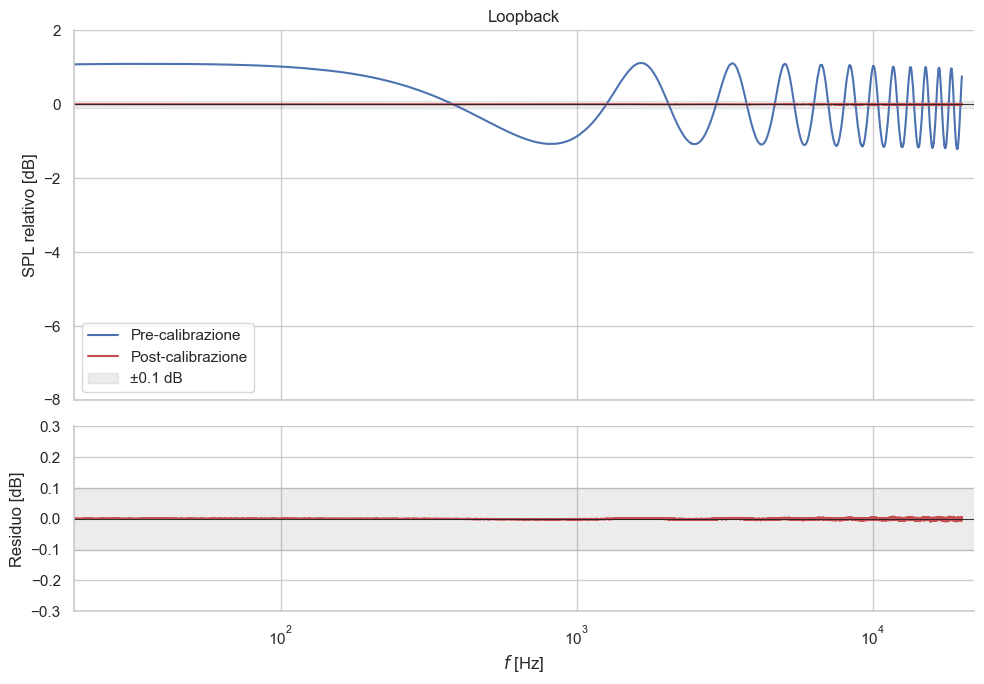

Ripple 0.02 dB: OK


In [2]:
def normalize(f, dB, f1=200, f2=2000):
    return dB - dB[(f >= f1) & (f <= f2)].mean()

f_nocal, dB_nocal = load_rew_export(CAL_TXT_DIR / 'ESS_NoCalibration.txt')
f_cal, dB_cal = load_rew_export(CAL_TXT_DIR / 'ESS_Calibrated.txt')
dB_nocal, dB_cal = normalize(f_nocal, dB_nocal), normalize(f_cal, dB_cal)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})
ax1.plot(f_nocal, dB_nocal, color=C[0], label='Pre-calibrazione')
for ax in (ax1, ax2):
    ax.plot(f_cal, dB_cal, color=C[3], label='Post-calibrazione')
    ax.axhline(0, color='k', lw=0.6)
    ax.axhspan(-0.1, 0.1, color='gray', alpha=0.15, label='±0.1 dB')
ax1.set(xscale='log', ylim=(-8, 2), ylabel='SPL relativo [dB]', title='Loopback')
ax1.legend()
ax2.set(xlim=(20, 22000), ylim=(-0.3, 0.3), xlabel='$f$ [Hz]', ylabel='Residuo [dB]')
plt.tight_layout()
fig.savefig(FIG_DIR / 'verifica_calibrazione_loopback.png', dpi=200)
plt.show()

ripple = np.ptp(dB_cal[(f_cal >= 20) & (f_cal <= 20000)])
print(f'Ripple {ripple:.2f} dB:', 'OK' if ripple < 0.4 else 'sopra il target (±0.2 dB)')

## Calcolo del file di calibrazione microfono

Residuo fra la misura della HS5 con l'ECM8000 e il datasheet, lisciato a 1/3 di ottava e allineato a 0 dB in 1–3 kHz. La correzione è limitata alla banda 1–16 kHz con raccordi a coseno rialzato di un'ottava: sotto domina la stanza, sopra la direttività della cassa.

Offset +89.31 dB, correzione -2.30…+4.34 dB, salto max 0.206 dB


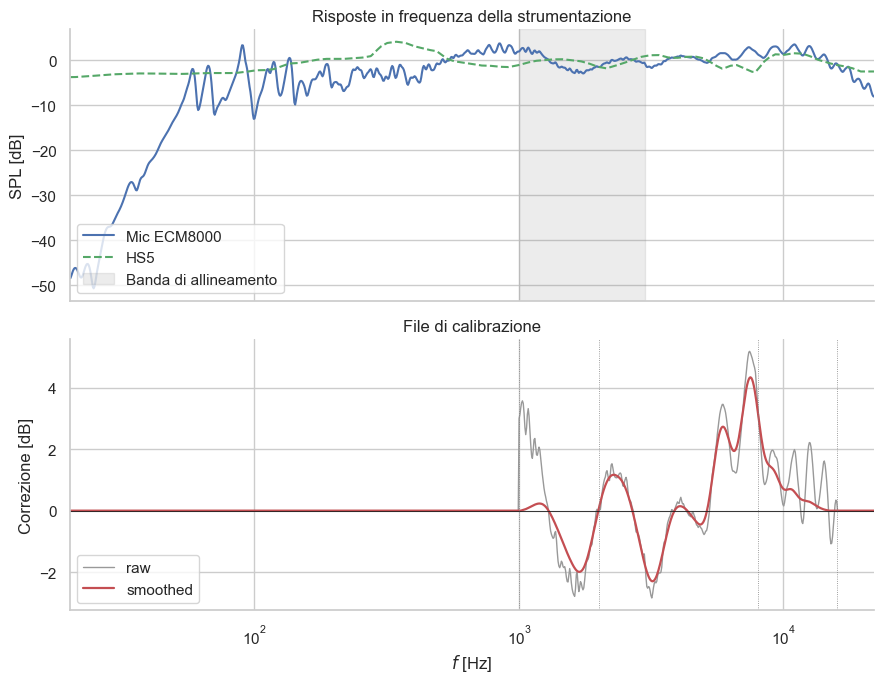

In [3]:
MEAS_FILE = CAL_TXT_DIR / 'Cal_ESS_02_ECM8000.txt'
OUT_FILE = CAL_DIR / 'ecm8000_mic.cal'
F_LOW, F_HIGH = 1000.0, 16000.0
F_ALIGN = (1000.0, 3000.0)
TAPER_OCT = 1.0
SMOOTH_FRAC = 3.0

f_meas, dB_meas = load_rew_export(MEAS_FILE)
dB_ref_meas = np.interp(f_meas, f_ref, dB_ref)
diff_raw = dB_meas - dB_ref_meas
diff = frac_octave_smooth(f_meas, diff_raw, fraction=SMOOTH_FRAC)
offset = diff[(f_meas >= F_ALIGN[0]) & (f_meas <= F_ALIGN[1])].mean()
cal_db = (diff - offset) * log_taper(f_meas, F_LOW, F_HIGH, octaves=TAPER_OCT)
cal_db[np.abs(cal_db) < 0.005] = 0.0  # evita '-0.00' nel file

write_cal_file(OUT_FILE, f_meas, cal_db, note=(
    'ECM8000 microphone calibration\n'
    f'Generated from {MEAS_FILE.name} vs {REF_FILE.name}\n'
    f'Smoothing 1/{SMOOTH_FRAC:.0f} oct, raised-cosine taper {F_LOW:.0f}-{F_HIGH:.0f} Hz '
    f'({TAPER_OCT:.0f} oct), aligned on {F_ALIGN[0]:.0f}-{F_ALIGN[1]:.0f} Hz\n'
    'Format: freq[Hz]  dB'))
print(f'Offset {offset:+.2f} dB, correzione {cal_db.min():+.2f}…{cal_db.max():+.2f} dB, '
      f'salto max {np.abs(np.diff(cal_db)).max():.3f} dB')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax1.plot(f_meas, dB_meas - offset, color=C[0], label='Mic ECM8000')
ax1.plot(f_meas, dB_ref_meas, '--', color=C[2], label='HS5')
ax1.axvspan(*F_ALIGN, color='gray', alpha=0.15, label='Banda di allineamento')
ax1.set(xscale='log', ylabel='SPL [dB]', title='Risposte in frequenza della strumentazione')
ax1.legend(loc='lower left')

cal_hard = np.where((f_meas >= F_LOW) & (f_meas <= F_HIGH), diff_raw - offset, 0.0)
ax2.plot(f_meas, cal_hard, lw=1, color='0.6', label='raw')
ax2.plot(f_meas, cal_db, lw=1.6, color=C[3], label='smoothed')
ax2.axhline(0, color='k', lw=0.6)
for fx in (F_LOW, F_LOW * 2**TAPER_OCT, F_HIGH / 2**TAPER_OCT, F_HIGH):
    ax2.axvline(fx, color='gray', lw=0.6, ls=':')
ax2.set(xlim=(20, 22000), xlabel='$f$ [Hz]', ylabel='Correzione [dB]', title='File di calibrazione')
ax2.legend(loc='lower left')
plt.tight_layout()
fig.savefig(FIG_DIR / 'calibrazione_ecm8000.png', dpi=200)
plt.show()